In [83]:
from typing import List, TypedDict, Literal
from pydantic import BaseModel , Field
import re
import logging
import asyncio

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_community.retrievers import BM25Retriever
from langchain_classic.retrievers import EnsembleRetriever
# from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_google_genai import ChatGoogleGenerativeAI , GoogleGenerativeAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langgraph.graph import StateGraph, START, END
from langchain_community.tools.tavily_search import TavilySearchResults
from dotenv import load_dotenv

load_dotenv()

True

In [84]:

logger = logging.getLogger("rag_pipeline")
logging.basicConfig(level=logging.INFO)

class LLMException(Exception):
    pass

async def safe_llm_invoke(chain, inputs, retries=2, delay=2, label=""):
    for attempt in range(1, retries + 1):
        try:
            return await chain.ainvoke(inputs)
        except Exception as e:
            logger.warning(f"[{label}] attempt {attempt}/{retries} failed: {e}")
            if attempt < retries:
                await asyncio.sleep(delay)
    logger.error(f"[{label}] all {retries} attempts failed, giving up.")
    raise LLMException(f"{label} failed after {retries} attempts")

In [ ]:

from pathlib import Path

BASE_DIR = Path(__file__).resolve().parent
PDF_PATH = BASE_DIR / "data" / "novatech_mini_rag_test.pdf"

docs = PyPDFLoader(str(PDF_PATH)).load()

In [86]:
chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(docs)
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")


In [87]:
embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")

In [88]:
vector_store = FAISS.from_documents(chunks, embeddings)
vector_retriever = vector_store.as_retriever(search_type="mmr", search_kwargs={"k": 4})

bm25_retriever = BM25Retriever.from_documents(chunks)
bm25_retriever.k = 4

# Hybrid Retrieval
retriever = EnsembleRetriever(retrievers = [bm25_retriever,vector_retriever],weights = [0.2,0.8])

INFO:httpx:HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents "HTTP/1.1 200 OK"


In [89]:
llm = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite",temperature=0)

In [90]:
UPPER_TH = 0.7
LOWER_TH = 0.4

In [91]:

class State(TypedDict):
    question: str

    docs: List[Document]
    good_docs: List[Document]
    verdict: str

    need_retrieval: bool
    retrieval_query: str
    rewrite_tries: int

    issup: Literal["fully_supported", "partially_supported", "no_support"]

  # knowledge refinement variables
    strips: List[str]
    kept_strips: List[str]
    refined_context: str

    web_query: str
    
    web_docs: List[Document]
    
    answer: str

In [92]:
class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(
        ...,
        description="True if external documents are needed to answer reliably, else False."
    )

decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)

should_retrieve_llm = llm.with_structured_output(RetrieveDecision)

async def decide_retrieval(state: "State"):
    decision = await safe_llm_invoke(should_retrieve_llm, decide_retrieval_prompt.format_messages(question=state["question"]), label="decide_retrieval")
    return {"need_retrieval": decision.should_retrieve}

# async def decide_retrieval(state: "State"):
#     decision: RetrieveDecision = await should_retrieve_llm.invoke(
#         decide_retrieval_prompt.format_messages(question=state["question"])
#     )
#     return {"need_retrieval": decision.should_retrieve}

In [93]:

def route_after_decide(state: State) -> Literal["generate_direct", "retrieve"]:
    return "retrieve" if state["need_retrieval"] else "generate_direct"

In [94]:

def retrieve_node(state: State) -> State:
    q = state.get("retrieval_query","") or state["question"]
    return {"docs": retriever.invoke(q)}


In [95]:

class DocScore(BaseModel):
    score: float

doc_eval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a strict retrieval evaluator for RAG.\n"
            "You will be given ONE retrieved chunk and a question.\n"
            "Return a relevance score in [0.0, 1.0].\n"
            "- 1.0: chunk alone is sufficient to answer fully/mostly\n"
            "- 0.0: chunk is irrelevant\n"
            "Be conservative with high scores.\n"
            "Output JSON only.",
        ),
        ("human", "Question: {question}\n\nChunk:\n{chunk}"),
    ]
)

doc_eval_chain = doc_eval_prompt | llm.with_structured_output(DocScore)

async def doc_relevance(state: State) -> State:
    q = state["question"]
    scores: List[float] = []
    good: List[Document] = []

    for d in state["docs"]:
        out = await safe_llm_invoke(doc_eval_chain, {"question": q, "chunk": d.page_content}, label="doc_relevance")
        scores.append(out.score)

        if out.score > LOWER_TH:
            good.append(d)

    if any(s > UPPER_TH for s in scores):
        return {
            "good_docs": good,
            "verdict": "CORRECT",
        }

    if len(scores) > 0 and all(s < LOWER_TH for s in scores):
        return {
            "good_docs": [],
            "verdict": "INCORRECT",
        }

    return {
        "good_docs": good,
        "verdict": "AMBIGUOUS",
    }


In [96]:

def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]

class KeepOrDrop(BaseModel):
    keep: bool

filter_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a strict relevance filter.\n"
            "Return keep=true only if the sentence directly helps answer the question.\n"
            "Use ONLY the sentence. Output JSON only.",
        ),
        ("human", "Question: {question}\n\nSentence:\n{sentence}"),
    ]
)

filter_chain = filter_prompt | llm.with_structured_output(KeepOrDrop)

async def refine(state: State) -> State:
    q = state["question"]

    if state.get("verdict") == "CORRECT":
        doc_content = state["good_docs"]
    elif state.get("verdict") == "INCORRECT":
        doc_content = state["web_docs"]
    else:  
         doc_content = state.get("good_docs") + state.get("web_docs",[])

    context = "\n\n".join(d.page_content for d in doc_content).strip()

    strips = decompose_to_sentences(context)

    kept: List[str] = []
    for s in strips:
        # if filter_chain.invoke({"question": q, "sentence": s}).keep:
        #     kept.append(s)
        out = await safe_llm_invoke(filter_chain, {"question": q, "sentence": s}, label="refine_filter")
        if out.keep:
            kept.append(s)

    refined_context = "\n".join(kept).strip()

    return {
        "strips": strips,
        "kept_strips": kept,
        "refined_context": refined_context,
    }


In [97]:

class WebQuery(BaseModel):
    query: str

rewrite_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Rewrite the user question into a web search query composed of keywords.\n"
            "Rules:\n"
            "- Keep it short (6–14 words).\n"
            "- If the question implies recency (e.g., recent/latest/last week/last month), add a constraint like (last 30 days).\n"
            "- Do NOT answer the question.\n"
            "- Return JSON with a single key: query",
        ),
        ("human", "Question: {question}"),
    ]
)

rewrite_chain = rewrite_prompt | llm.with_structured_output(WebQuery)

async def rewrite_query_node(state: State) -> State:
    # out = rewrite_chain.invoke({"question": state["question"]})
    out = await safe_llm_invoke(rewrite_chain, {"question": state["question"]}, label="rewrite_query_node")
    return {"web_query": out.query}

tavily = TavilySearchResults(max_results=5)

def web_search_node(state: State) -> State:
    q = state.get("web_query") or state["question"]
    results = tavily.invoke({"query": q})

    web_docs: List[Document] = []
    for r in results or []:
        title = r.get("title", "")
        url = r.get("url", "")
        content = r.get("content", "") or r.get("snippet", "")
        text = f"TITLE: {title}\nURL: {url}\nCONTENT:\n{content}"
        web_docs.append(Document(page_content=text, metadata={"url": url, "title": title}))

    return {"web_docs": web_docs}


In [98]:

answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a helpful ML tutor. Answer ONLY using the provided context.\n"
            "If the context is empty or insufficient and need_retrieval is false, then give the answer based on your knowledge without hallucinating or else say : i don't know",
        ),
        ("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)
async def generate(state: State) -> State:
    # out = (answer_prompt | llm).invoke({"question": state["question"], "context": state.get("refined_context","")})
    out = await safe_llm_invoke(answer_prompt | llm, {"question": state["question"], "context": state.get("refined_context","")}, label="generate")
    return {"answer": out.content}


In [99]:
ans_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a helpful tutor.\n"
            "Give the answer based on your knowledge without hallucinating or else say : i don't know",
        ),
        ("human", "Question: {question}\n\n"),
    ]
)
async def direct_generate(state: State) -> State:
    # out = (ans_prompt | llm).invoke({"question": state["question"]})
    out = await safe_llm_invoke(ans_prompt | llm, {"question": state["question"]}, label="direct_generate")
    return {"answer": out.content}

In [100]:

def decesion_node(state: State) -> str:
    if state["verdict"] == "CORRECT":
        return "refine"
    else:
        return "rewrite_query"


In [101]:

class IsSUPDecision(BaseModel):
    issup: Literal["fully_supported", "partially_supported", "no_support"]

issup_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are verifying whether the ANSWER is supported by the CONTEXT.\n"
            "Return JSON with keys: issup\n"
            "issup must be one of: fully_supported, partially_supported, no_support.\n\n"
            "How to decide issup:\n"
            "- fully_supported:\n"
            "  Every meaningful claim is explicitly supported by CONTEXT, and the ANSWER does NOT introduce\n"
            "  any qualitative/interpretive words that are not present in CONTEXT.\n"
            "  (Examples of disallowed words unless present in CONTEXT: culture, generous, robust, designed to,\n"
            "  supports professional development, best-in-class, employee-first, etc.)\n\n"
            "- partially_supported:\n"
            "  The core facts are supported, BUT the ANSWER includes ANY abstraction, interpretation, or qualitative\n"
            "  phrasing not explicitly stated in CONTEXT (e.g., calling policies 'culture', saying leave is 'generous',\n"
            "  or inferring outcomes like 'supports professional development').\n\n"
            "- no_support:\n"
            "  The key claims are not supported by CONTEXT.\n\n"
            "Rules:\n"
            "- Be strict: if you see ANY unsupported qualitative/interpretive phrasing, choose partially_supported.\n"
            "- If the answer is mostly unrelated to the question or unsupported, choose no_support.\n"
            "- Do not use outside knowledge."
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Answer:\n{answer}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)
issup_llm = llm.with_structured_output(IsSUPDecision)

async def is_sup(state: State):
    # decision: IsSUPDecision = await issup_llm.invoke(
    #     issup_prompt.format_messages(
    #         question=state["question"],
    #         answer=state.get("answer", ""),
    #         context=state.get("refined_context", ""),
    #     )
    # )
    decision = await safe_llm_invoke(issup_llm, 
                                     issup_prompt.format_messages(question=state["question"], answer=state.get("answer",""), context=state.get("refined_context","")), label="is_sup")
    return {"issup": decision.issup}

MAX_RETRIES = 2
def route_after_issup(state: State) -> Literal["accept_answer", "revise_answer"]:
    if state.get("issup") == "fully_supported":
        return "accept_answer"
    if state.get("rewrite_tries", 0) >= MAX_RETRIES:
        return "accept_answer" 

    return "revise_answer"

In [102]:
class RewriteDecision(BaseModel):
    retrieval_query: str = Field(
        ...,
        description="Rewritten query optimized for vector retrieval against internal company PDFs."
    )

rewrite_for_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Rewrite the user's QUESTION into a query optimized for vector retrieval over INTERNAL company PDFs.\n\n"
            "Rules:\n"
            "- Keep it short (6–16 words).\n"
            "- Preserve key entities (e.g., NexaAI, plan names).\n"
            "- Add 2–5 high-signal keywords that likely appear in policy/pricing docs.\n"
            "- Remove filler words.\n"
            "- Do NOT answer the question.\n"
            "- Output JSON with key: retrieval_query\n\n"
            "Examples:\n"
            "Q: 'Do NexaAI plans include a free trial?'\n"
            "-> {{'retrieval_query': 'NexaAI free trial duration trial period plans'}}\n\n"
        ),
        (
            "human",
            "QUESTION:\n{question}\n\n"
            "Previous retrieval query (if any):\n{retrieval_query}\n\n"
            "Answer (if any):\n{answer}"
        ),
    ]
)



rewrite_llm = llm.with_structured_output(RewriteDecision)

async def rewrite_question(state: State):
    # decision: RewriteDecision = rewrite_llm.invoke(
    #     rewrite_for_retrieval_prompt.format_messages(
    #         question=state["question"],
    #         retrieval_query=state.get("retrieval_query", ""),
    #         answer=state.get("answer", ""),
    #     )
    # )
    decision = await safe_llm_invoke(rewrite_llm, 
                                      rewrite_for_retrieval_prompt.format_messages(question=state["question"], retrieval_query=state.get("retrieval_query",""), answer=state.get("answer","")), label="rewrite_question")

    return {
        "retrieval_query": decision.retrieval_query,
        "rewrite_tries": state.get("rewrite_tries", 0) + 1,
        "docs": [],
    }


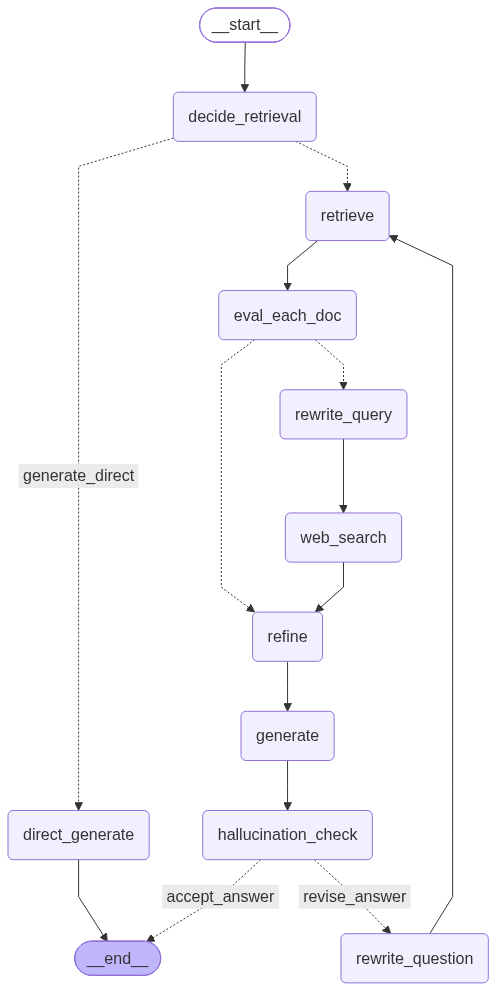

In [103]:

graph = StateGraph(State)

graph.add_node("decide_retrieval", decide_retrieval)
graph.add_node("retrieve", retrieve_node)
graph.add_node("eval_each_doc",doc_relevance)
graph.add_node("rewrite_query", rewrite_query_node)
graph.add_node("web_search", web_search_node)
graph.add_node("refine", refine)
graph.add_node("generate", generate)
graph.add_node("direct_generate",direct_generate)
graph.add_node("hallucination_check",is_sup)
graph.add_node("rewrite_question",rewrite_question)

graph.add_edge(START, "decide_retrieval")
graph.add_conditional_edges("decide_retrieval", route_after_decide, {"retrieve":"retrieve","generate_direct":"direct_generate"})
graph.add_edge("direct_generate",END)
graph.add_edge("retrieve", "eval_each_doc")
graph.add_conditional_edges(
    "eval_each_doc",
    decesion_node,
    { "refine": "refine","rewrite_query": "rewrite_query"}
)
graph.add_edge("rewrite_query", "web_search")
graph.add_edge("web_search", "refine")
graph.add_edge("refine", "generate")
# graph.add_edge("generate", END)
graph.add_edge("generate", "hallucination_check")
graph.add_conditional_edges("hallucination_check", route_after_issup,
    {
        "accept_answer": END,
        "revise_answer": "rewrite_question",
    },
)
# graph.add_edge("hallucination_check",END)
graph.add_edge("rewrite_question", "retrieve")


app = graph.compile()

app


In [ ]:

res = await app.ainvoke(
    {
        "question": "who is the ceo of Novatech",
        "docs": [],
        "good_docs": [],
        "verdict": "",
        "need_retrieval": False ,
        "strips": [],
        "kept_strips": [],
        "refined_context": "",
        "web_query": "",
        "web_docs": [],
        "answer": "",
    }
)

print("VERDICT:", res["verdict"])
print("need_retrieval :", res["need_retrieval"])
# print("IS_SUP", res["issup"])
print("\nOUTPUT:\n", res["answer"])
